In [5]:
from matplotlib import pyplot as plt
import numpy as np
import networkx as nx
import timeit
from src.max_clique_github.max_clique.main import get_max_clique
from src.classical_algorithms import find_max_clique_rec
from tqdm import tqdm
import json

# plt.rcParams.update({
#     "text.usetex": True,
#     "font.family": "Helvetica"
# })

Plot maxclique run time for different densities for ER graphs for different algorithms

In [21]:
def benchmark_algorithm_densities(algorithm, n, samples=50, steps=30, solution_existence=False):
    # with open(filepath, "w") as f:
    #     data = json.load(f)
    times = np.zeros((steps))
    expansions = np.zeros((steps))
    ps = np.linspace(0.001, 0.999, steps)
    s_times = np.zeros((samples))
    s_expansions = np.zeros((samples))
    counters = np.zeros((steps))
    for i,p in tqdm(enumerate(ps)):
        solution_counter = 0
        for s in range(samples):
            graph = nx.erdos_renyi_graph(n, p)
            t1 = timeit.default_timer()
            mc, expanded = algorithm(graph)
            if solution_existence and (mc != None or mc != 0):
                solution_counter += 1
            t2 = timeit.default_timer()
            s_times[s] = t2 - t1
            s_expansions[s] = expanded

        counters[i] = solution_counter / samples
        mean_time = s_times.mean()
        std_time = s_times.std()
        filtered_s_times = s_times[s_times < mean_time + std_time*2]
        mean_time = filtered_s_times.mean()
        times[i] = mean_time

        mean_expansions = s_expansions.mean()
        std_expansions = s_expansions.std()
        filtered_s_expansions = s_expansions[s_expansions < mean_expansions + std_expansions*2]
        mean_expansions = filtered_s_expansions.mean()
        expansions[i] = mean_expansions

    return ps, (times, expansions), counters

In [56]:
samples = 50
steps = 100
ps1, data1, _ = benchmark_algorithm_densities(lambda graph: find_max_clique_rec(graph, set(), set(graph.nodes()), set(), 0), 20, samples=samples, steps=steps)
ps2, data2, _ = benchmark_algorithm_densities(lambda graph: find_max_clique_rec(graph, set(), set(graph.nodes()), set(), 0), 30, samples=samples, steps=steps)
ps3, data3, _ = benchmark_algorithm_densities(lambda graph: find_max_clique_rec(graph, set(), set(graph.nodes()), set(), 0), 40, samples=samples, steps=steps)

100it [00:01, 60.01it/s]
100it [00:18,  5.30it/s]
100it [04:25,  2.65s/it]


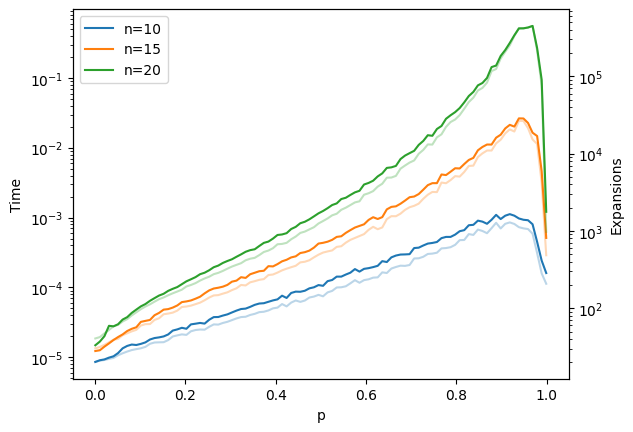

In [57]:

fig, ax1 = plt.subplots()

ax1.plot(ps1, data1[0], label="n=10", color="tab:blue")
ax1.plot(ps2, data2[0], label="n=15", color="tab:orange")
ax1.plot(ps3, data3[0], label="n=20", color="tab:green")

ax1.set_yscale("log")
ax1.set_ylabel("Time")
ax1.set_xlabel("p")

ax2 = ax1.twinx()

ax2.plot(ps1, data1[1], label="n=10", color="tab:blue", alpha=0.3)
ax2.plot(ps2, data2[1], label="n=15", color="tab:orange", alpha=0.3)
ax2.plot(ps3, data3[1], label="n=20", color="tab:green", alpha=0.3)

ax2.set_yscale("log")
ax2.set_ylabel("Expansions")
ax2.set_xlabel("p")

ax1.legend()
plt.show()

In [55]:
plt.savefig("Figures/classic_maxclique_er_p.png")

<Figure size 640x480 with 0 Axes>

plot probability for QA on maxclique problem, different ER p

Samples per p: 5312
[np.float64(0.638401749089124), np.float64(0.46129094779903557), np.float64(0.45845622934366265), np.float64(0.4978408372795468), np.float64(0.5471138940470568), np.float64(0.5840376137621082), np.float64(0.6050932999545088), np.float64(0.6158656177587222), np.float64(0.6200928219536616), np.float64(0.6078066323923823), np.float64(0.6016480902283764), np.float64(0.5955021356153488), np.float64(0.5935843107572564), np.float64(0.5944675682375882), np.float64(0.6018128062353769), np.float64(0.6148039810356746), np.float64(0.6232582278582578), np.float64(0.6392933497441862), np.float64(0.6478435406601966), np.float64(0.6579375596478846), np.float64(0.6615316551386118), np.float64(0.6693745319245995), np.float64(0.6709626069734078), np.float64(0.6732036625329618), np.float64(0.6722028576472323), np.float64(0.6762811384788342), np.float64(0.6822483427023252), np.float64(0.6909924302870544), np.float64(0.6972161568157165), np.float64(0.7085579951743509), np.float64(0.70787

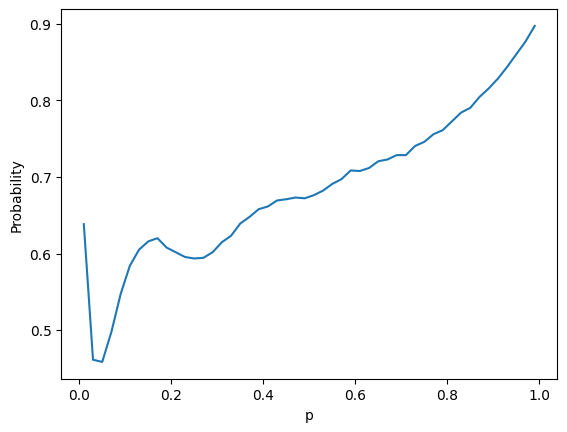

In [19]:
with open("benchmarkResults/energies/qa_energies_results_maxclique_er_p.json", "r") as f:
    data = json.load(f)

probs_per_p = []
ps = [s["p"] for s in data["sizes"]]
for results in data["samples"]:
    probs_per_p.append(np.mean([r["prob"] for r in results]))
print(f"Samples per p: {len(data["samples"][0])}")
print(probs_per_p)
plt.figure()
plt.plot(ps, np.array(probs_per_p))
# plt.yscale("log")
# plt.plot(ps2, data2)
# plt.plot(ps3, data3)
plt.ylabel("Probability")
plt.xlabel("p")
plt.savefig("Figures/qa_maxclique_er_p_n10.png")
plt.show()

plot QAOA success probability for maxclique with different ER p

Samples per p: 90
[np.float64(0.32222222222222224), np.float64(0.25555555555555554), np.float64(0.2), np.float64(0.13333333333333333), np.float64(0.14444444444444443), np.float64(0.17777777777777778), np.float64(0.06666666666666667), np.float64(0.08888888888888889), np.float64(0.06666666666666667), np.float64(0.1), np.float64(0.06666666666666667), np.float64(0.05555555555555555), np.float64(0.08888888888888889), np.float64(0.03333333333333333), np.float64(0.044444444444444446), np.float64(0.044444444444444446), np.float64(0.07777777777777778), np.float64(0.044444444444444446), np.float64(0.13333333333333333), np.float64(0.1), np.float64(0.06666666666666667), np.float64(0.13333333333333333), np.float64(0.044444444444444446), np.float64(0.06666666666666667), np.float64(0.07777777777777778), np.float64(0.06666666666666667), np.float64(0.08888888888888889), np.float64(0.1), np.float64(0.12222222222222222), np.float64(0.12222222222222222), np.float64(0.12222222222222222), np.float64(0.15555

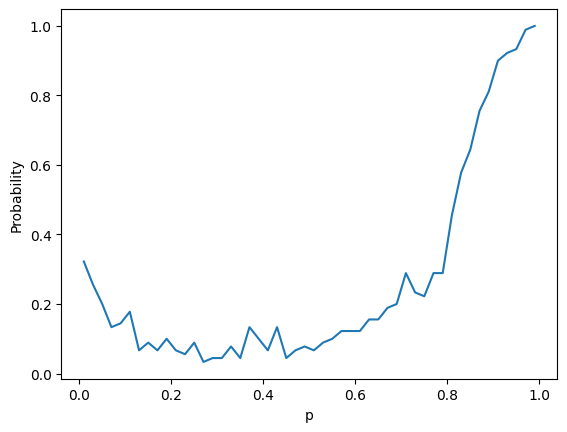

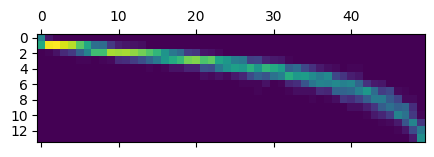

In [20]:
with open("benchmarkResults/qaoa_results_maxclique_er_p_n14.json", "r") as f:
    data = json.load(f)

max_k = 14
probs_per_p = []
ps = [s["p"] for s in data["problem_sizes"]]
mc_size_per_p = np.zeros((max_k, len(ps)))
for i, results in enumerate(data["results_per_size"]):
    probs_per_p.append(np.mean([1 if r["found_solution"] else 0 for r in results]))
    for r in results:
        mc_size_per_p[r["k"]-1, i] += 1
print(f"Samples per p: {len(data["results_per_size"][0])}")
print(probs_per_p)
plt.figure()
plt.plot(ps, np.array(probs_per_p))
# plt.yscale("log")
# plt.plot(ps2, data2)
# plt.plot(ps3, data3)
plt.ylabel("Probability")
plt.xlabel("p")
plt.savefig("Figures/qaoa_maxclique_er_p_n14.png")
plt.show()

fig = plt.figure(figsize=(5, 5))
plt.matshow(mc_size_per_p, fignum=fig.number)
plt.show()

Phase transition for k-clique problem at different ER #nodes and p

In [15]:
from src.utils import count_k_cliques, has_k_clique
samples = 500
ps1, times1, counters1 = benchmark_algorithm_densities(lambda x: True if has_k_clique(x, 5) else None, 10, steps=50, samples=samples, solution_existence=True)
ps2, times2, counters2 = benchmark_algorithm_densities(lambda x: True if has_k_clique(x, 7) else None, 15, steps=50, samples=samples, solution_existence=True)
ps3, times3, counters3 = benchmark_algorithm_densities(lambda x: True if has_k_clique(x, 10) else None, 30, steps=50, samples=samples, solution_existence=True)

50it [00:00, 68.20it/s] 
50it [00:01, 31.24it/s]
50it [00:09,  5.22it/s]


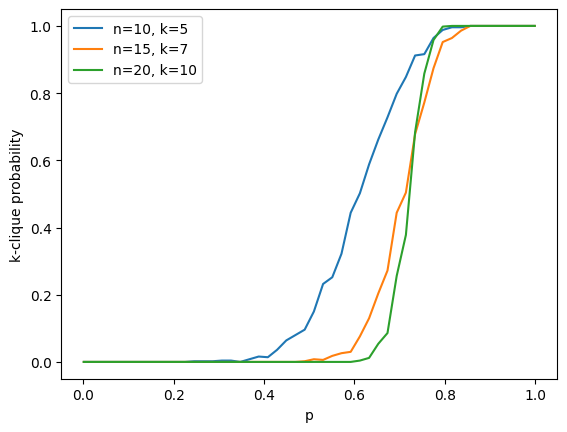

In [16]:
plt.figure()
plt.plot(ps1, counters1, label="n=10, k=5")
plt.plot(ps2, counters2, label="n=15, k=7")
plt.plot(ps3, counters3, label="n=20, k=10")
plt.legend()
plt.xlabel("p")
plt.ylabel("k-clique probability")
plt.show()